## Part 7: The Conditional Gaussian ## 

Conditional Density of $Y$ given $X = x$ 

Let $(X, Y)$ be jointly Gaussian with mean $\mu_ = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$ and covariance $\Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix}$ 

Conditional density is defined by $$f_{Y/X}(\mid x) = \frac{f_{X,Y}(x, y)}{f_X(x)}$$ 

##  Part 7.1: Conditional Mean ## 
$\mu_{Y/X=x} = \rho\frac{\sigma_Y}{\sigma_X}x = (0.5)\frac{2}{2}x = 0.5x$ 

##  Part 7.1: Conditional Variance ## 
$\sigma_{Y|X=x}^2 = \sigma_Y^2(1-\rho^2) = 4(1-0.5^2) = 3$ 

##  Part 7.2: General Partitioned Gaussian Vector ## 
$\begin{bmatrix} Y \\ X \end{bmatrix} \sim \mathcal{N}\left(\begin{bmatrix} \mu_Y \\ \mu_X\end{bmatrix}, \begin{bmatrix} \Sigma_{YY} & \Sigma_{YX} \\ \Sigma_{XY} & \Sigma_{XX} \end{bmatrix}\right)$, the conditional distribution $Y$ given $X=x$ is Gaussian with: 
$$\mu_{Y|X=x} = \mu_Y + \Sigma_{YX} \Sigma_{XX}^{-1}(x- \mu_X)$$ 
$$\Sigma_{Y|X=x} = \Sigma_{YY} - \Sigma_{YX}\Sigma_{XX}^{-1}\Sigma_{XY}$$ 

##  Part 7.2: Special Case ## 
$mu_X = 0$, $\mu_Y = 0$, $\Sigma_{XX} = 4$, $\Sigma_{YY} = 4$, and $\Sigma_{YX} = \Sigma_{XY} = 2$
$$\mu_{Y|X=x} = 0 + 2(4)^{-1}(x-0) = 0.5x, \qquad \Sigma_{Y/X=x} = 4 -2(4)^{1}(2) = 4-1 = 3$$

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from mp3lib import sample_mean_cov, is_valid_covariance

SEED = 1506714529 
rng = np.random.default_rng(SEED) 
rng_step7 = rng.spawn(1)[0]

N = 1000000
mu = np.array([0, 0])
sigma = np.array([[4, 2], [2, 4]]) 

## verify validity using library functions 
print("\n-----------------------")
print("STEP 7: Conditional Gaussian")
print("-----------------------") 
print(f"is_valid_covariance(sigma): {is_valid_covariance(sigma)}")

samples = rng_step7.multivariate_normal(mu, sigma, size = N) 
## check empirical mean and covariance using library 
mu_emp, sigma_emp = sample_mean_cov(samples) 
print(f"Empirical mean: {np.round(mu_emp, 5)}")
print(f" Joint covariance Frobenius error: {np.linalg.norm(sigma_emp - sigma, ord = 'fro'):.5f}")

X = samples[:, 0]
Y = samples[:, 1] 
## create bins 
bin_edges = np.linspace(-5, 5, 41)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

valid_centers = []
cond_mean = []
cond_mean_std = []
cond_var = []

for i in range(len(bin_edges) - 1):
    in_bin = ( X >= bin_edges[i]) & (X < bin_edges[i+1])
    count = np.sum(in_bin)

    if count >= 50: 
        y_bin = Y[in_bin]
        valid_centers.append(bin_centers[i])
        cond_mean.append(np.mean(y_bin))
        cond_var.append(np.var(y_bin, ddof=1))
        cond_mean_std.append(np.std(y_bin, ddof=1) / np.sqrt(count))

valid_centers= np.array(valid_centers)
cond_mean = np.array(cond_mean)
cond_var = np.array(cond_var)
cond_mean_std = np.array(cond_mean_std) 

(slope, intercept), cov_fit = np.polyfit(valid_centers, cond_mean, deg= 1, cov = True)
slope_std = np.sqrt(cov_fit[0,0])
slope_diff = abs(slope - .5)

##compare conditional var over theortical
mean_cond_var= np.mean(cond_var)
var_diff = abs(mean_cond_var - 3)
var_std = np.std(cond_var, ddof=1) / np.sqrt(len(cond_var)) 

print("\n----------------------")
print("7.3: Binned Conditional Mean")
print("----------------------") 
print(f"Analytical Slope:  0.5000")
print(f"Fitted empirical slope: {slope:.5f} \u00b1 {slope_std:.5f}")
print(f"Absolute Difference: {slope_diff:.5f} ({slope_diff / slope_std:.2f} standard errors)")
print(f"Fitted Intercept: {intercept:.5f} (Theory: 0.0000)") 

print("\n----------------------")
print("7.4: Binned Conditional Variance")
print("----------------------") 
print (f"Analytical variance: 3.0000")
print(f"Mean binned variance: {mean_cond_var:.5f} \u00b1 {var_std:.5f}")
print(f"Absolute Difference: {var_diff:.5f}")



-----------------------
STEP 7: Conditional Gaussian
-----------------------
is_valid_covariance(sigma): True
Empirical mean: [0.00027 0.00041]
 Joint covariance Frobenius error: 0.01060

----------------------
7.3: Binned Conditional Mean
----------------------
Analytical Slope:  0.5000
Fitted empirical slope: 0.50017 ± 0.00090
Absolute Difference: 0.00017 (0.20 standard errors)
Fitted Intercept: 0.00199 (Theory: 0.0000)

----------------------
7.4: Binned Conditional Variance
----------------------
Analytical variance: 3.0000
Mean binned variance: 3.00344 ± 0.00698
Absolute Difference: 0.00344


## Part 7.4 ## 
Shown analytically and empirically, variance of the gaussian Y given X=x does not depend on x. Given the equation $\sigma_{Y|X=x}^2 = \sigma_Y^2(1-\rho^2)$ we can see that x is not on the right side. When holding X=x to the same constant we can treat Y as the variable, where in other distributions shape changes with the conditioning value, making this a special case. 

## Part 7.5 ## 
For the jointly gaussian vector, conditioning a variable yields another gaussian whose mean is linear. Since MMSE is already linear it makes it optimal over a nonlinear estimator, not just convenient. 


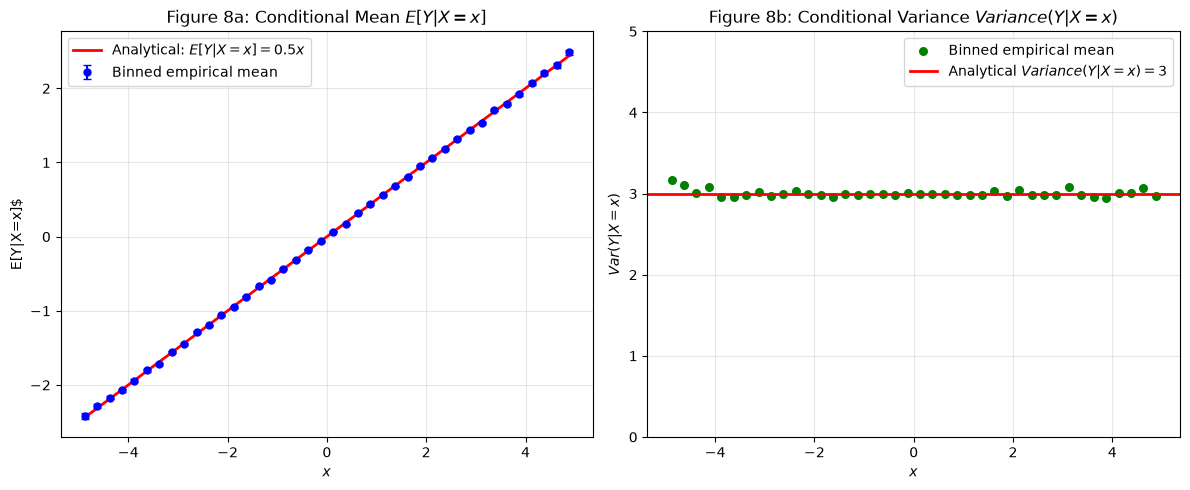

In [2]:
fig, axes = plt.subplots(1,2, figsize = (12,5))

## panel 1 
axes[0].errorbar(valid_centers, cond_mean, yerr = cond_mean_std, fmt="o",
                 color="blue", markersize = 5, capsize = 3, label ="Binned empirical mean")
axes[0].plot(valid_centers, 0.5 * valid_centers, "r-", linewidth = 2,
        label = "Analytical: $E[Y|X=x] = 0.5x$")
axes[0].set_title("Figure 8a: Conditional Mean $E[Y|X=x]$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("E[Y|X=x]$")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

## panel 2 
axes[1].scatter(valid_centers, cond_var, color="green", s=30,
                 label ="Binned empirical mean")
axes[1].axhline(3, color="r", linestyle = "-", linewidth= 2,
                label = "Analytical $Variance(Y|X=x) = 3$")
axes[1].set_ylim(0,5)
axes[1].set_title("Figure 8b: Conditional Variance $Variance(Y|X=x)$")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$Var(Y|X=x)$")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Figure 8 Interpretation ## 
Figure 8a shows binned empirical means lying directly on the analytical line that is equal to 0.5 with a slope of 0.50017. Matching the theoretical slope within 0.20 standard errors. Figure 8b shows empirical conditional variances flat along a horizontal line of analyitcal variance equal to 3. This confirms visually that Y does not depend on X. 